# 03: DNA Methylation Preprocessing

Full preprocessing pipeline from raw SeSAMe beta-value files to a selected feature matrix for LUAD vs LUSC classification.

**Pipeline**
| Step | Action |
|------|--------|
| 1 | Discover all methylation `.txt` files (LUAD + LUSC) |
| 2 | Map file UUIDs → patient barcodes via GDC API |
| 3 | Load all beta-value files and build CpG × patient matrix |
| 4 | Load labels and align cohort |
| 5 | Load train/test split |
| 6 | Drop CpG sites with >20% missing values |
| 7 | Impute remaining missing values with row median (train-derived) |
| 8 | Welch t-test  -  identify differentially methylated CpG sites (train only) |
| 9 | ExtraTreesClassifier feature selection (train only, 95% cumulative importance) |
| 10 | Visualise results |
| 11 | Save final feature matrix |


> **Output:** `methylation_selected_features.csv`, (N_patients × K CpG sites)

## Imports and Configuration

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import requests
import json
from pathlib import Path
from scipy import stats
from sklearn.ensemble import ExtraTreesClassifier
from tqdm import tqdm
import warnings
warnings.filterwarnings('ignore')

In [2]:
# Paths
import os

BASE_DIR = Path(
    os.environ.get("FUSION_REPO_DIR", str(Path.cwd()))
).expanduser().resolve()

if BASE_DIR.name in {"Preprocessing", "Training"}:
    BASE_DIR = BASE_DIR.parent

if not (BASE_DIR / "Training" / "07_controlled_early_late_fusion.ipynb").is_file():
    raise RuntimeError(
        "Start Jupyter from the repository directory or set FUSION_REPO_DIR."
    )
DATA_DIR = Path(
    os.environ.get("FUSION_DATA_DIR", str(BASE_DIR / "Data"))
).expanduser().resolve()
METH_DIR  = DATA_DIR / 'methylation'

OUT_DIR = BASE_DIR / "Preprocessing"
FIG_DIR   = OUT_DIR / 'Figures'
FIG_DIR.mkdir(parents=True, exist_ok=True)

LABELS_PATH = DATA_DIR / "multiomics_labels.tsv"
SPLIT_PATH    = DATA_DIR / 'train_test_split.csv'
OUT_PATH      = OUT_DIR  / 'methylation_selected_features.csv'
SELECTOR_PATH = OUT_DIR  / 'methylation_selected_cpgs.txt'
CACHE_PATH    = OUT_DIR  / 'methylation_uuid_barcode_map.json'

In [3]:
# Configurations
RANDOM_STATE      = 42
MISS_THRESHOLD    = 0.20   # drop CpG sites with >20% missing values
PVAL_THRESHOLD    = 0.001  # Welch t-test p-value threshold for differential methylation
IMPORTANCE_THRESH = 0.95   # cumulative importance threshold for feature selection
GDC_API           = 'https://api.gdc.cancer.gov'

In [4]:
print('Imports OK')
print(f'Methylation dir : {METH_DIR}')
print(f'Output          : {OUT_PATH}')

Imports OK
Methylation dir : /scratch/cdse815/fall_2025/gmriechi/Lung-Cancer-Subtyping/Data/methylation
Output          : /scratch/cdse815/fall_2025/gmriechi/Lung-Cancer-Subtyping/Multimodal-Analysis/Preprocessing/methylation_selected_features.csv


## 1. Discover all methylation `.txt` files

In [5]:
luad_files = list((METH_DIR / 'TCGA-LUAD').rglob('*.methylation_array.sesame.level3betas.txt'))
lusc_files = list((METH_DIR / 'TCGA-LUSC').rglob('*.methylation_array.sesame.level3betas.txt'))
all_files  = {f.parent.name: f for f in luad_files + lusc_files}

print(f'LUAD files : {len(luad_files)}')
print(f'LUSC files : {len(lusc_files)}')
print(f'Total      : {len(all_files)}')
print(f'\nExample UUID : {list(all_files.keys())[0]}')
print(f'Example path : {list(all_files.values())[0]}')

LUAD files : 473
LUSC files : 370
Total      : 843

Example UUID : 02c085f9-c641-427c-9cb6-51720e3f4a3e
Example path : /scratch/cdse815/fall_2025/gmriechi/Lung-Cancer-Subtyping/Data/methylation/TCGA-LUAD/DNA_Methylation/Methylation_Beta_Value/02c085f9-c641-427c-9cb6-51720e3f4a3e/639097ee-9965-42ba-bbdb-d385d2f91fbe.methylation_array.sesame.level3betas.txt


## 2. Map file UUIDs to patient barcodes via GDC API

Same approach as RNA-Seq. Results are cached to avoid repeated API calls on re-runs.

In [6]:
def query_gdc_batch(uuids):
    payload = {
        'filters': json.dumps({
            'op': 'in',
            'content': {'field': 'file_id', 'value': uuids}
        }),
        'fields': 'file_id,cases.submitter_id',
        'format': 'json',
        'size'   : str(len(uuids))
    }
    r = requests.post(f'{GDC_API}/files', data=payload, timeout=60)
    r.raise_for_status()
    result = {}
    for hit in r.json()['data']['hits']:
        fid   = hit['file_id']
        cases = hit.get('cases', [])
        if cases:
            result[fid] = cases[0]['submitter_id'][:12].upper()
    return result

if CACHE_PATH.exists():
    with open(CACHE_PATH) as f:
        uuid_to_patient = json.load(f)
    print(f'Loaded cached UUID map : {len(uuid_to_patient)} entries')
else:
    uuid_to_patient = {}
    uuids = list(all_files.keys())
    for i in tqdm(range(0, len(uuids), 1000), desc='GDC API'):
        uuid_to_patient.update(query_gdc_batch(uuids[i:i+1000]))
    with open(CACHE_PATH, 'w') as f:
        json.dump(uuid_to_patient, f)
    print(f'Mapped {len(uuid_to_patient)} / {len(uuids)} files to patient barcodes')

Loaded cached UUID map : 843 entries


## 3. Load beta-value files and build CpG × patient matrix

Each file contains two tab-separated columns with no header: CpG probe ID and beta value (0–1).
One sample per patient is retained (first occurrence).

In [7]:
def load_beta_file(filepath):
    """Load a single SeSAMe beta-value file.
    Returns a Series indexed by CpG probe ID.
    """
    df = pd.read_csv(
        filepath, sep='\t', header=None,
        names=['cpg_id', 'beta_value'],
        na_values=['NA', 'na', '']
    )
    return df.set_index('cpg_id')['beta_value'].astype(float)

beta_dict = {}
skipped   = []

for uuid, filepath in tqdm(all_files.items(), desc='Loading files'):
    patient_id = uuid_to_patient.get(uuid)
    if patient_id is None:
        skipped.append(uuid); continue
    if patient_id in beta_dict:
        continue  # one sample per patient
    try:
        beta_dict[patient_id] = load_beta_file(filepath)
    except Exception:
        skipped.append(uuid)

# Build CpG × patients matrix
df_beta = pd.DataFrame(beta_dict)   # rows=CpGs, cols=patients
print(f'Patients loaded  : {len(beta_dict)}')
print(f'Skipped          : {len(skipped)}')
print(f'Beta matrix shape: {df_beta.shape}  (CpGs × patients)')

Loading files: 100%|██████████| 843/843 [02:17<00:00,  6.13it/s]


Patients loaded  : 828
Skipped          : 0
Beta matrix shape: (486427, 828)  (CpGs × patients)


## 4. Load labels and align cohort

In [8]:
df_labels = pd.read_csv(LABELS_PATH, sep='\t', index_col='patient_id')
df_labels.index = df_labels.index.str.strip().str.upper().str[:12]
labels = df_labels['subtype_simple'].map({'LUAD': 0, 'LUSC': 1})

common_ids = df_beta.columns.intersection(labels.index)
df_beta    = df_beta[common_ids]
y          = labels.loc[common_ids]

print(f'Patients after intersection : {len(common_ids)}')
print(f'LUAD: {(y==0).sum()}, LUSC: {(y==1).sum()}')

Patients after intersection : 826
LUAD: 456, LUSC: 370


## 5. Load train/test split

In [9]:
assert SPLIT_PATH.exists(), f'Split file not found: {SPLIT_PATH}. Run notebook 01 first.'
split_df  = pd.read_csv(SPLIT_PATH, index_col='patient_id')
split_df.index = split_df.index.str.strip().str.upper().str[:12]
split_df  = split_df.loc[split_df.index.intersection(common_ids)]

train_ids = split_df[split_df['split'] == 'train'].index
test_ids  = split_df[split_df['split'] == 'test'].index

print(f'Train : {len(train_ids)}')
print(f'Test  : {len(test_ids)}')

Train : 579
Test  : 247


## 6. Drop CpG sites with >20% missing values

Missing value fraction computed across all patients.
CpG sites failing this threshold are too sparse to be reliable features.

In [10]:
miss_frac = df_beta.isnull().mean(axis=1)   # per CpG

print(f'Total CpG sites          : {len(miss_frac):,}')
print(f'CpGs with any missing    : {(miss_frac > 0).sum():,}')
print(f'CpGs >20% missing (drop) : {(miss_frac > MISS_THRESHOLD).sum():,}')

Total CpG sites          : 486,427
CpGs with any missing    : 188,905
CpGs >20% missing (drop) : 75,470


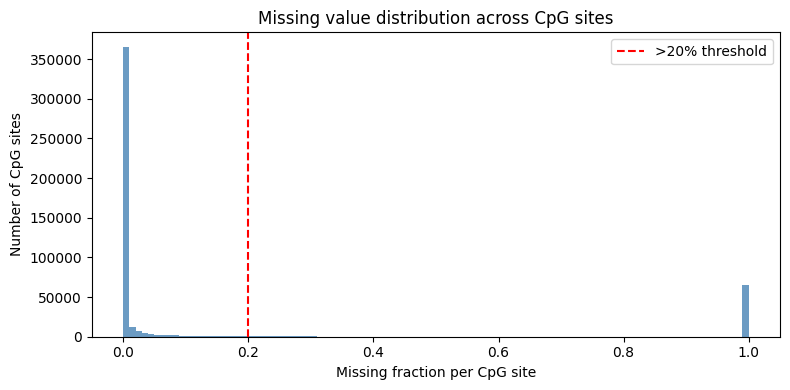

Figure saved to /scratch/cdse815/fall_2025/gmriechi/Lung-Cancer-Subtyping/Multimodal-Analysis/Preprocessing/Figures/methylation_missing_values.png


In [11]:
# Visualize
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(miss_frac, bins=100, color='steelblue', edgecolor='none', alpha=0.8)
ax.axvline(MISS_THRESHOLD, color='red', linestyle='--', linewidth=1.5,
           label=f'>{MISS_THRESHOLD:.0%} threshold')
ax.set_xlabel('Missing fraction per CpG site')
ax.set_ylabel('Number of CpG sites')
ax.set_title('Missing value distribution across CpG sites')
ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / 'methylation_missing_values.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Figure saved to {FIG_DIR}/methylation_missing_values.png')

In [12]:
# Drop
df_beta = df_beta.loc[miss_frac[miss_frac <= MISS_THRESHOLD].index]
print(f'\nCpG sites retained : {df_beta.shape[0]:,}')


CpG sites retained : 410,957


## 7. Impute remaining missing values with row median

Row medians are computed from **training patients only** to prevent leakage, then applied to the full matrix.

In [13]:
print(f'NaNs before imputation : {df_beta.isnull().sum().sum():,}')

# Compute row medians on train patients only
train_medians = df_beta[train_ids].median(axis=1)

# Apply to full matrix
df_beta = df_beta.T   # patients × CpGs for easier row-wise fill
df_beta = df_beta.fillna(train_medians)
df_beta = df_beta.T   # back to CpGs × patients

print(f'NaNs after imputation  : {df_beta.isnull().sum().sum():,}')
print(f'Beta matrix shape      : {df_beta.shape}')

NaNs before imputation : 2,304,877


NaNs after imputation  : 0
Beta matrix shape      : (410957, 826)


## 8. Welch t-test, differentially methylated CpG sites (train only)

Two-tailed Welch t-test between LUAD and LUSC training patients.
CpG sites passing p ≤ 0.001 are considered differentially methylated.
These form the candidate pool for feature selection.

In [14]:
# Transpose for easier indexing: patients × CpGs
df_beta_T = df_beta.T

train_beta = df_beta_T.loc[train_ids]
X_luad     = train_beta.loc[y.loc[train_ids] == 0]
X_lusc     = train_beta.loc[y.loc[train_ids] == 1]

print('Running Welch t-test on CpG sites...')
_, p_vals = stats.ttest_ind(X_lusc.values, X_luad.values, axis=0, equal_var=False)

# Mean beta difference per CpG
mean_diff = X_lusc.mean(axis=0).values - X_luad.mean(axis=0).values

diff_df  = pd.DataFrame({
    'mean_diff': mean_diff,
    'abs_diff' : np.abs(mean_diff),
    'pval'     : p_vals
}, index=df_beta.index)

sig_cpgs = diff_df[diff_df['pval'] <= PVAL_THRESHOLD].sort_values('abs_diff', ascending=False)

print(f'Total CpG sites tested        : {len(diff_df):,}')
print(f'Differentially methylated     : {len(sig_cpgs):,}  (p≤{PVAL_THRESHOLD})')
print(f'\nTop 10 CpG sites by |beta diff|:')
print(sig_cpgs[['mean_diff', 'abs_diff', 'pval']].head(10).to_string())

Running Welch t-test on CpG sites...
Total CpG sites tested        : 410,957
Differentially methylated     : 182,445  (p≤0.001)

Top 10 CpG sites by |beta diff|:
            mean_diff  abs_diff           pval
cpg_id                                        
cg18121066  -0.592692  0.592692  6.029760e-113
cg17945789  -0.502148  0.502148   1.071940e-73
cg03555299  -0.492138  0.492138  2.135498e-100
cg03130248  -0.479014  0.479014   6.032801e-71
cg14696311  -0.476996  0.476996   5.002398e-79
cg17510385  -0.475928  0.475928   1.632071e-94
cg24884444  -0.471132  0.471132   2.425791e-72
cg13387113  -0.469248  0.469248   2.072780e-95
cg12222244  -0.465466  0.465466  2.135097e-100
cg24597774  -0.462590  0.462590   9.633385e-83


### 8a. Top CpG sites mean beta value comparison

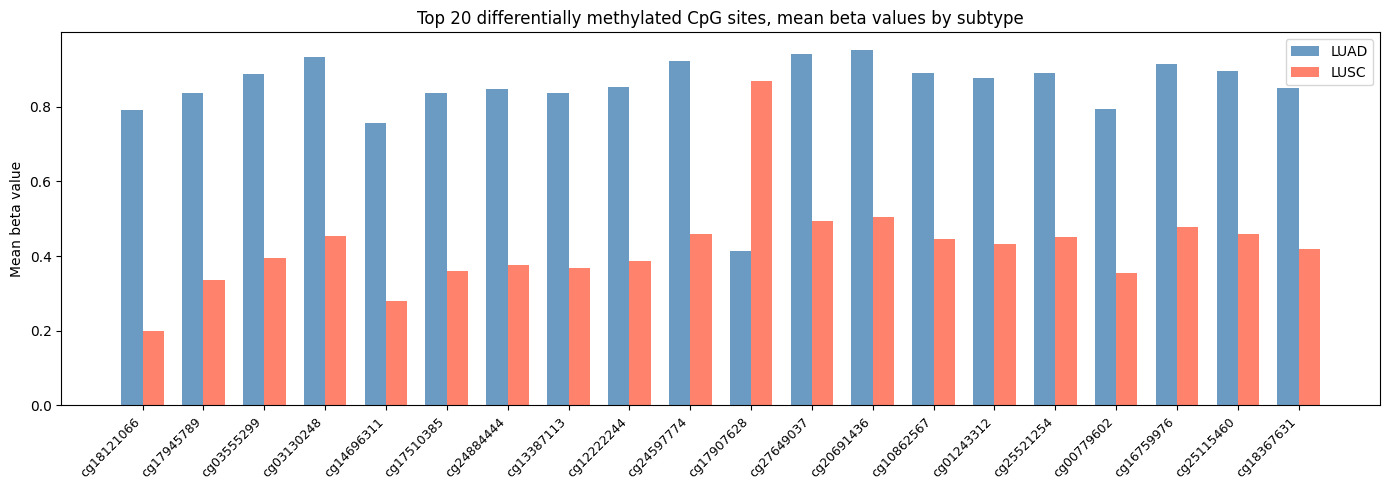

Figure saved to /scratch/cdse815/fall_2025/gmriechi/Lung-Cancer-Subtyping/Multimodal-Analysis/Preprocessing/Figures/methylation_top20_beta.png


In [15]:
top20_cpgs   = sig_cpgs.head(20).index.tolist()
luad_means   = X_luad[top20_cpgs].mean(axis=0)
lusc_means   = X_lusc[top20_cpgs].mean(axis=0)

x     = np.arange(len(top20_cpgs))
width = 0.35
fig, ax = plt.subplots(figsize=(14, 5))
ax.bar(x - width/2, luad_means, width, label='LUAD', color='steelblue', alpha=0.8)
ax.bar(x + width/2, lusc_means, width, label='LUSC', color='tomato',    alpha=0.8)
ax.set_xticks(x); ax.set_xticklabels(top20_cpgs, rotation=45, ha='right', fontsize=9)
ax.set_ylabel('Mean beta value')
ax.set_title('Top 20 differentially methylated CpG sites, mean beta values by subtype')
ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / 'methylation_top20_beta.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Figure saved to {FIG_DIR}/methylation_top20_beta.png')

### 8b. Filter matrix to differentially methylated CpG sites

In [16]:
df_diff = df_beta_T[sig_cpgs.index].copy()   # patients × significant CpGs
print(f'Differentially methylated CpG matrix : {df_diff.shape}  (patients × CpGs)')

Differentially methylated CpG matrix : (826, 182445)  (patients × CpGs)


## 9. ExtraTreesClassifier feature selection (train set only)

Fitted on training patients only to rank CpG sites by discriminative importance.
Features retained until 95% cumulative importance is covered.

In [17]:
X_train = df_diff.loc[train_ids]
y_train = y.loc[train_ids]

print(f'X_train : {X_train.shape}')
print('Fitting ExtraTreesClassifier...')

etc = ExtraTreesClassifier(
    n_estimators=500,
    max_features='sqrt',
    random_state=RANDOM_STATE,
    n_jobs=-1
)
etc.fit(X_train, y_train)

importances = pd.Series(etc.feature_importances_, index=df_diff.columns)
importances = importances.sort_values(ascending=False)
cumulative  = importances.cumsum() / importances.sum()

# Methylation importance is flat across 182k CpGs, use fixed top-N
# Select top 100 CpGs by absolute mean beta-value difference (train-derived)
N_TOP_CPGS = 100
top_cpgs   = sig_cpgs.head(N_TOP_CPGS).index.tolist()

print(f'Differentially methylated CpGs : {len(sig_cpgs):,}')
print(f'Selected (top by |beta diff|)  : {N_TOP_CPGS}')
print(f'\nTop 20 selected CpG sites:')
for i, (cpg, row) in enumerate(sig_cpgs.head(20).iterrows(), 1):
    print(f'  {i:>2}. {cpg:<15} mean_diff={row["mean_diff"]:+.4f}  pval={row["pval"]:.2e}')

X_train : (579, 182445)
Fitting ExtraTreesClassifier...
Differentially methylated CpGs : 182,445
Selected (top by |beta diff|)  : 100

Top 20 selected CpG sites:
   1. cg18121066      mean_diff=-0.5927  pval=6.03e-113
   2. cg17945789      mean_diff=-0.5021  pval=1.07e-73
   3. cg03555299      mean_diff=-0.4921  pval=2.14e-100
   4. cg03130248      mean_diff=-0.4790  pval=6.03e-71
   5. cg14696311      mean_diff=-0.4770  pval=5.00e-79
   6. cg17510385      mean_diff=-0.4759  pval=1.63e-94
   7. cg24884444      mean_diff=-0.4711  pval=2.43e-72
   8. cg13387113      mean_diff=-0.4692  pval=2.07e-95
   9. cg12222244      mean_diff=-0.4655  pval=2.14e-100
  10. cg24597774      mean_diff=-0.4626  pval=9.63e-83
  11. cg17907628      mean_diff=+0.4545  pval=7.20e-98
  12. cg27649037      mean_diff=-0.4463  pval=1.04e-83
  13. cg20691436      mean_diff=-0.4461  pval=3.66e-76
  14. cg10862567      mean_diff=-0.4443  pval=5.80e-101
  15. cg01243312      mean_diff=-0.4419  pval=1.02e-85
  16. cg2

### 9a. Feature importance visualization

NameError: name 'n_selected' is not defined

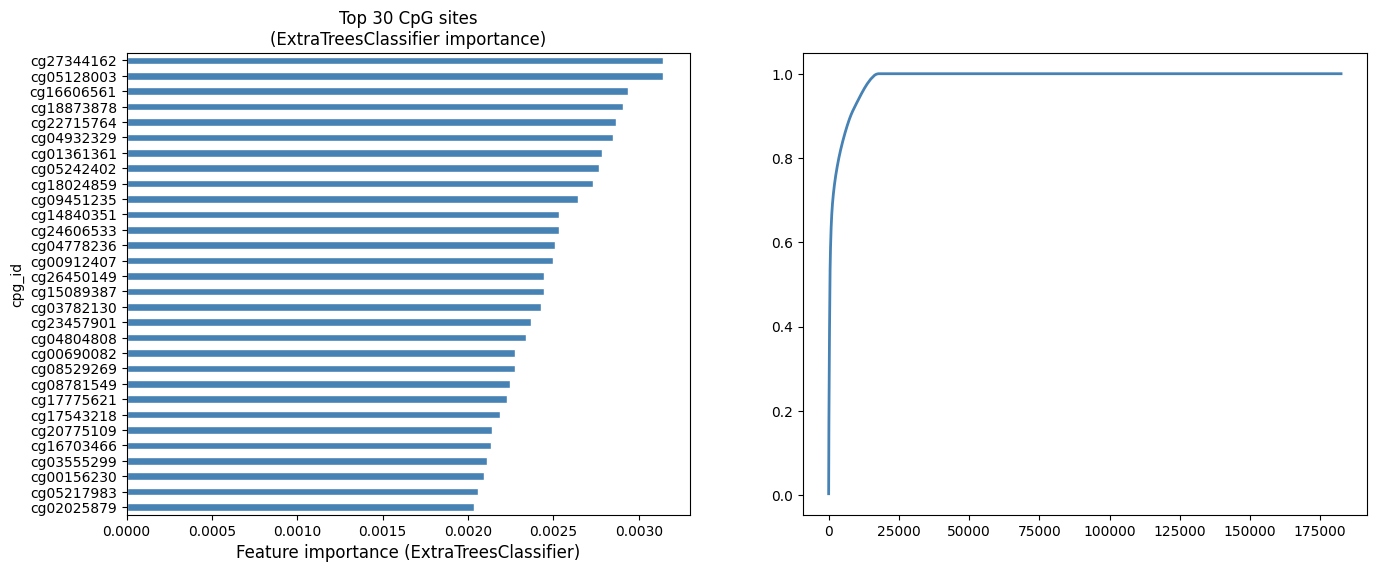

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

ax = axes[0]
importances.iloc[:30].sort_values().plot(
    kind='barh', ax=ax, color='steelblue', edgecolor='white')
ax.set_xlabel('Feature importance (ExtraTreesClassifier)', fontsize=12)
ax.set_title('Top 30 CpG sites\n(ExtraTreesClassifier importance)', fontsize=12)

ax2 = axes[1]
ax2.plot(range(1, len(cumulative) + 1), cumulative.values, color='steelblue', linewidth=2)
ax2.axvline(n_selected, color='red', linestyle='--', linewidth=1.5,
            label=f'Cutoff: {n_selected} CpGs')
ax2.axhline(IMPORTANCE_THRESH, color='orange', linestyle=':', linewidth=1.5,
            label=f'{IMPORTANCE_THRESH:.0%} threshold')
ax2.scatter([n_selected], [coverage], color='red', zorder=5, s=60)
ax2.set_xlabel('Number of CpG sites', fontsize=12)
ax2.set_ylabel('Cumulative importance', fontsize=12)
ax2.set_title('Cumulative feature importance\n(DNA methylation modality)', fontsize=12)
ax2.legend(fontsize=10)
ax2.set_ylim(0, 1.05)
plt.tight_layout()
plt.savefig(FIG_DIR / 'methylation_feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Figure saved to {FIG_DIR}/methylation_feature_importance.png')

### 9b. Methylation heatmap of selected CpG sites

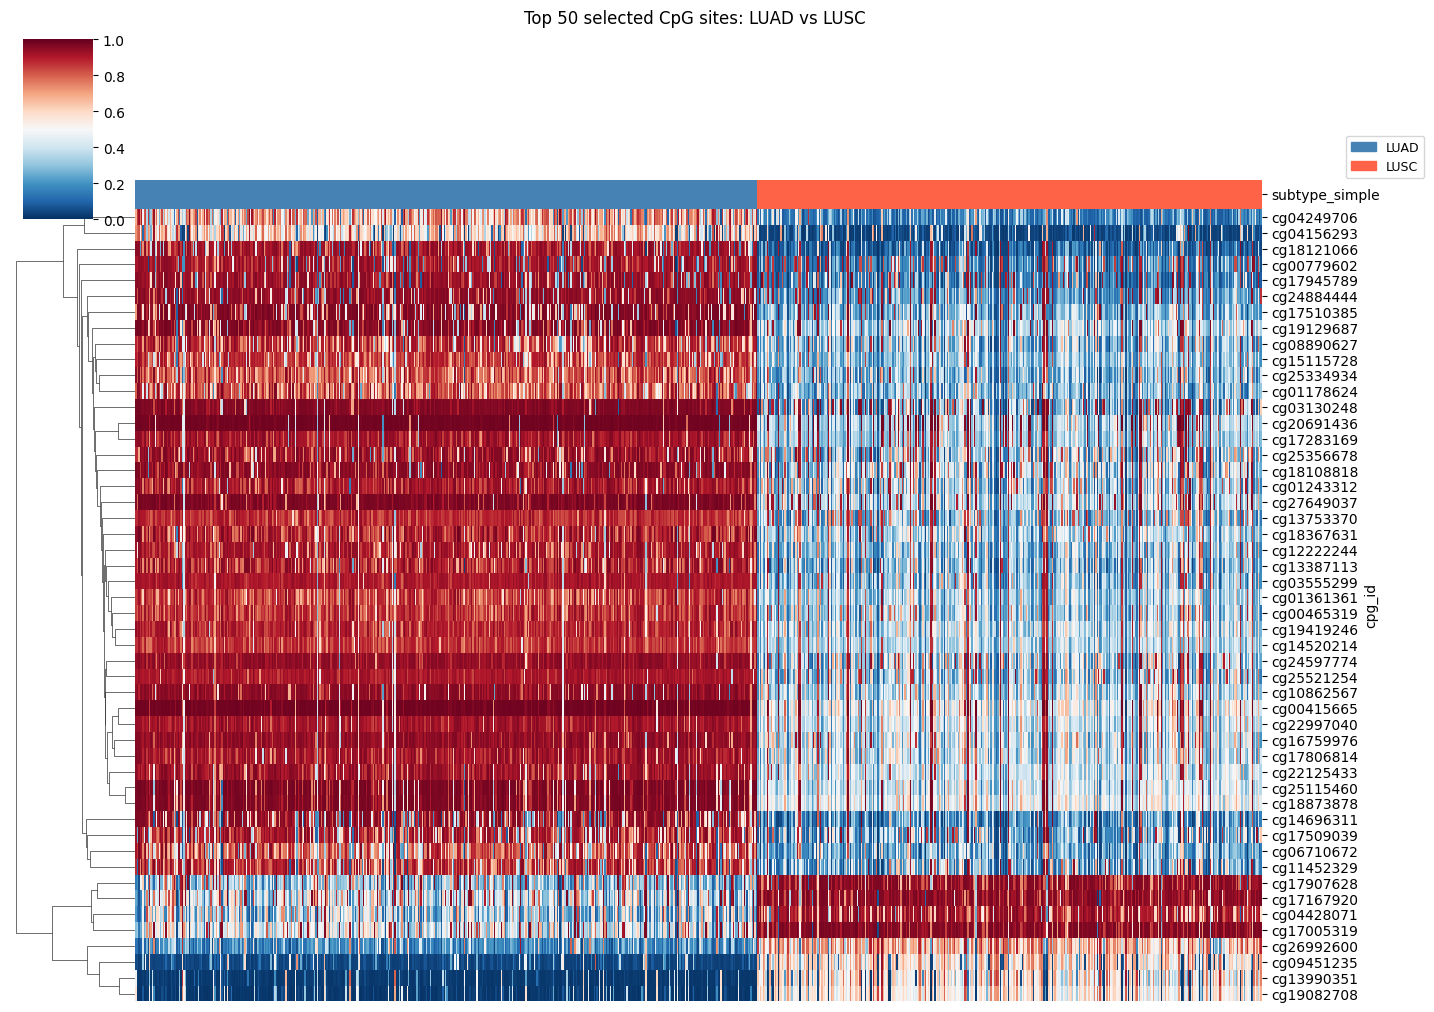

Figure saved to /scratch/cdse815/fall_2025/gmriechi/Lung-Cancer-Subtyping/GraphBased-Analysis/MORPHEUS/notebooks/Multimodal-Analysis/Preprocessing/Figures/methylation_heatmap.png


In [ ]:
top_plot       = top_cpgs[:min(50, n_selected)]
patient_order  = y.sort_values().index
df_heat        = df_diff[top_plot].loc[patient_order].T
subtype_colors = y.loc[patient_order].map({0: 'steelblue', 1: 'tomato'})

g = sns.clustermap(
    df_heat,
    col_colors       = subtype_colors,
    cmap             = 'RdBu_r',
    center           = 0.5,
    vmin             = 0, vmax=1,
    yticklabels      = True,
    xticklabels      = False,
    figsize          = (14, 10),
    dendrogram_ratio = (0.1, 0.15),
    col_cluster      = False,
)
g.fig.suptitle(f'Top {len(top_plot)} selected CpG sites: LUAD vs LUSC', y=1.01, fontsize=12)
luad_patch = mpatches.Patch(color='steelblue', label='LUAD')
lusc_patch = mpatches.Patch(color='tomato',    label='LUSC')
g.ax_heatmap.legend(handles=[luad_patch, lusc_patch],
                    loc='upper right', bbox_to_anchor=(1.15, 1.1), fontsize=9)
plt.savefig(FIG_DIR / 'methylation_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Figure saved to {FIG_DIR}/methylation_heatmap.png')

In [ ]:
df_final = df_diff[top_cpgs].copy()

df_final.to_csv(OUT_PATH)
print(f'Saved feature matrix to {OUT_PATH}')
print(f'Shape                : {df_final.shape}  (patients × CpG sites)')

with open(SELECTOR_PATH, 'w') as f:
    f.write('\n'.join(top_cpgs))
print(f'CpG names saved      to {SELECTOR_PATH}')

print(f'Selected : {n_selected} CpG sites (top by |mean beta difference|)')
print(f'Dropped  : {len(sig_cpgs) - n_selected} differentially methylated CpGs')

Saved feature matrix to /scratch/cdse815/fall_2025/gmriechi/Lung-Cancer-Subtyping/GraphBased-Analysis/MORPHEUS/notebooks/Multimodal-Analysis/Preprocessing/methylation_selected_features.csv
Shape                : (826, 100)  (patients × CpG sites)
CpG names saved      to /scratch/cdse815/fall_2025/gmriechi/Lung-Cancer-Subtyping/GraphBased-Analysis/MORPHEUS/notebooks/Multimodal-Analysis/Preprocessing/methylation_selected_cpgs.txt
Selected : 100 CpG sites (top by |mean beta difference|)
Dropped  : 182345 differentially methylated CpGs


## Summary

| Step | Result |
|------|--------|
| Raw files (LUAD + LUSC) | 473 + 370 = 843 |
| Total CpG sites | 486,427 |
| After dropping >20% missing | 410,957 |
| After Welch t-test (p≤0.001) | 182,445 |
| **Final selected CpG sites** | **100 (top by \|mean beta difference\|)** |
| Output file | `methylation_selected_features.csv` |
| Feature selection | Top 100 CpGs by absolute mean beta-value difference (train set only) |
| Leakage prevention | Row medians, t-test, and selection all computed on train patients only |